# Лабораторная работа 7. Прогноз временного ряда
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Разберите перенос градиента через три момента. Затем сравните простой RNN,
GRU и LSTM с прогнозом по последнему отсчёту. Ряд генерируется локально.
Для второго этапа нужны PyTorch и приложенный Python_Code/Chapter_07/rnn_forecasting.py.

## 1. Три шага BPTT
Используйте $a_t=wx_t+uh_{t-1}+b$, $h_t=\tanh(a_t)$ и
$\widehat y_t=vh_t+c$. Потеря — половина суммы квадратов по трём моментам.
Перед запуском вычислите $a_1$ и $\widehat y_1$, а затем проследите вклад будущей
дельты в формулу $\delta_t=(v(\widehat y_t-y_t)+u\delta_{t+1})(1-h_t^2)$.

In [1]:
from math import isclose
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
package = next(
    (p for p in (cwd, *cwd.parents) if (p / "Python_Code/Chapter_07/rnn_bptt_numeric.py").is_file()),
    None,
)
if package is None:
    raise FileNotFoundError("Откройте блокнот вместе с папкой Python_Code учебника.")
sys.path.insert(0, str(package / "Python_Code/Chapter_07"))
from rnn_bptt_numeric import main as verify_bptt

verify_bptt()

lstm_c=0.460000 lstm_h=0.258051 gru_h=0.360000
states=[0.71629787, -0.329128946, 0.323396351]
deltas=[0.082486281, -0.524127678, -0.227712271]
gradients=[0.492757824, -0.30048484, -0.669353668, 0.319005696, -0.24732167]
loss=0.165091370427->0.094477742883 truncated_du=-0.227764438434
manual_autograd_finite_difference_checks=passed


## 2. Общий протокол прогнозирования
Каждую временную часть нарезают отдельно. Одно окно содержит 48 наблюдений.
Выход — три прогноза на горизонты 1, 3 и 6. Параметры стандартизации получены
по обучающему отрезку. Короткий режим использует 1200 отсчётов и две эпохи,
полный — 6000 отсчётов и восемь эпох.

In [2]:
from rnn_forecasting import main

PROFILE = "short"
SEED = 42
HORIZONS = (1, 3, 6)
expected_test_windows = {"short": 187, "full": 1147}[PROFILE]
print(f"profile={PROFILE}, seed={SEED}, ожидается тестовых окон: {expected_test_windows}")

profile=short, seed=42, ожидается тестовых окон: 187


## 3. Модели и независимая сверка ошибок
Запустите один и тот же протокол для всех моделей. Тестовые прогнозы и цели
возвращены в исходной шкале. Сравните опубликованные ошибки с пересчётом
из массива разностей по каждому горизонту.

In [3]:
results = main(["--profile", PROFILE, "--seed", str(SEED)])
assert set(results) == {"Persistence", "RNN", "GRU", "LSTM"}
for name, values in results.items():
    truth = values["truth"].reshape(-1, len(HORIZONS))
    prediction = values["prediction"].reshape_as(truth)
    assert tuple(truth.shape) == (expected_test_windows, 3)
    residual = prediction - truth
    mae = residual.abs().mean(dim=0).tolist()
    rmse = residual.square().mean(dim=0).sqrt().tolist()
    for observed, saved in zip(mae + rmse, list(values["mae"]) + list(values["rmse"])):
        assert isclose(observed, saved, rel_tol=1e-5, abs_tol=1e-7)
    assert all(a <= r + 1e-7 for a, r in zip(mae, rmse))
    print(f"Сверено {name}: MAE {[round(x, 4) for x in mae]}, "
          f"RMSE {[round(x, 4) for x in rmse]}")

torch=2.10.0+cpu device=cpu seed=42 profile=short observations=1200 history=48 horizons=(1, 3, 6)
train_windows=667 val_windows=187 test_windows=187 train_mean=0.005470 train_std=0.761107

Persistence
parameters=0 best_epoch=None val_rmse=0.454032
horizon=1 test_mae=0.156177 test_rmse=0.199241
horizon=3 test_mae=0.311205 test_rmse=0.384892
horizon=6 test_mae=0.538538 test_rmse=0.650189

RNN


epoch=1 train_mse_scaled=0.988893 val_rmse=0.696874 grad_max_before_clip=1.2559 clipped_batches=5/6
epoch=2 train_mse_scaled=0.721386 val_rmse=0.574939 grad_max_before_clip=1.3403 clipped_batches=3/6
parameters=1219 best_epoch=2 val_rmse=0.574939
horizon=1 test_mae=0.411471 test_rmse=0.482627
horizon=3 test_mae=0.460673 test_rmse=0.545236
horizon=6 test_mae=0.559880 test_rmse=0.658573

GRU


epoch=1 train_mse_scaled=0.912376 val_rmse=0.694665 grad_max_before_clip=0.8288 clipped_batches=0/6
epoch=2 train_mse_scaled=0.750859 val_rmse=0.618209 grad_max_before_clip=0.8396 clipped_batches=0/6
parameters=3459 best_epoch=2 val_rmse=0.618209
horizon=1 test_mae=0.481546 test_rmse=0.560463
horizon=3 test_mae=0.525633 test_rmse=0.613938
horizon=6 test_mae=0.553942 test_rmse=0.649843

LSTM


epoch=1 train_mse_scaled=0.943601 val_rmse=0.724358 grad_max_before_clip=0.6696 clipped_batches=0/6
epoch=2 train_mse_scaled=0.834238 val_rmse=0.667619 grad_max_before_clip=0.5240 clipped_batches=0/6
parameters=4579 best_epoch=2 val_rmse=0.667619
horizon=1 test_mae=0.524787 test_rmse=0.609346
horizon=3 test_mae=0.565294 test_rmse=0.659399
horizon=6 test_mae=0.593169 test_rmse=0.695604
Сверено Persistence: MAE [0.1562, 0.3112, 0.5385], RMSE [0.1992, 0.3849, 0.6502]
Сверено RNN: MAE [0.4115, 0.4607, 0.5599], RMSE [0.4826, 0.5452, 0.6586]
Сверено GRU: MAE [0.4815, 0.5256, 0.5539], RMSE [0.5605, 0.6139, 0.6498]
Сверено LSTM: MAE [0.5248, 0.5653, 0.5932], RMSE [0.6093, 0.6594, 0.6956]


## 4. MAE на разных горизонтах
Сравнивайте столбцы внутри одной группы. Один короткий запуск показывает
работоспособность протокола. Вывод о полном опыте формулируйте по его собственным результатам.

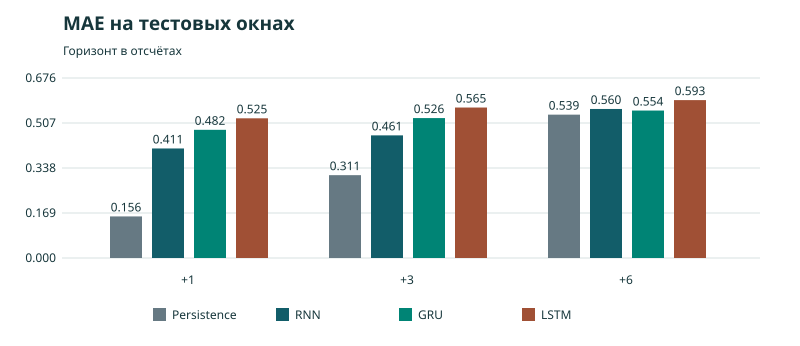

In [4]:
from IPython.display import SVG, display

names = ("Persistence", "RNN", "GRU", "LSTM")
colors = ("#667983", "#125d69", "#008475", "#a05035")
maximum = 1.14 * max(max(results[n]["mae"]) for n in names)
base, height = 258, 180
parts = []
for fraction in (0, .25, .5, .75, 1):
    y = base - height * fraction
    parts.append(f'<path d="M62 {y} H760" stroke="#d7e1e1"/>')
    parts.append(f'<text x="56" y="{y+4}" text-anchor="end">{maximum*fraction:.3f}</text>')
for j, horizon in enumerate(HORIZONS):
    origin = 110 + j * 219
    parts.append(f'<text x="{origin+78}" y="284" text-anchor="middle">+{horizon}</text>')
    for k, (name, color) in enumerate(zip(names, colors)):
        value = results[name]["mae"][j]
        bar = height * value / maximum
        x, y = origin + k * 42, base - bar
        parts.append(f'<rect x="{x}" y="{y:.2f}" width="32" height="{bar:.2f}" fill="{color}"/>')
        parts.append(f'<text x="{x+16}" y="{y-5:.2f}" text-anchor="middle">{value:.3f}</text>')
for k, (name, color) in enumerate(zip(names, colors)):
    x = 153 + k * 123
    parts.append(f'<rect x="{x}" y="308" width="13" height="13" fill="{color}"/>')
    parts.append(f'<text x="{x+19}" y="319">{name}</text>')
svg = (
    '<svg xmlns="http://www.w3.org/2000/svg" width="800" height="346" '
    'viewBox="0 0 800 346" font-family="sans-serif" font-size="12" fill="#16363b" '
    'role="img" aria-label="MAE четырёх методов на трёх горизонтах">'
    '<rect width="800" height="346" fill="white"/>'
    '<text x="63" y="30" font-size="19" font-weight="bold">MAE на тестовых окнах</text>'
    '<text x="63" y="55">Горизонт в отсчётах</text>'
    + "".join(parts) + "</svg>"
)
display(SVG(svg))

## 5. Самостоятельная работа
**A.** Вручную вычислите три дельты и производные по w и u. Проверьте число окон.

**B.** Сравните короткий и полный профили. Для каждого горизонта оцените выигрыш
или проигрыш относительно прогноза по последнему значению.

**C.** Повторите полный опыт с другим seed. Заранее укажите, какая валидационная
метрика определит выбор и какой горизонт важнее для вашего применения.